In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliothèques chargées avec succès")

Bibliothèques chargées avec succès


In [61]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame

In [62]:
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df["species"] = df["species"].map({0: "setosa", 1: "versicolor", 2: "virginica"})
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [63]:
df.shape

(150, 5)

In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [65]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [66]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [67]:
df.duplicated().sum()

np.int64(1)

In [68]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [69]:
sns.set_theme(style="whitegrid")

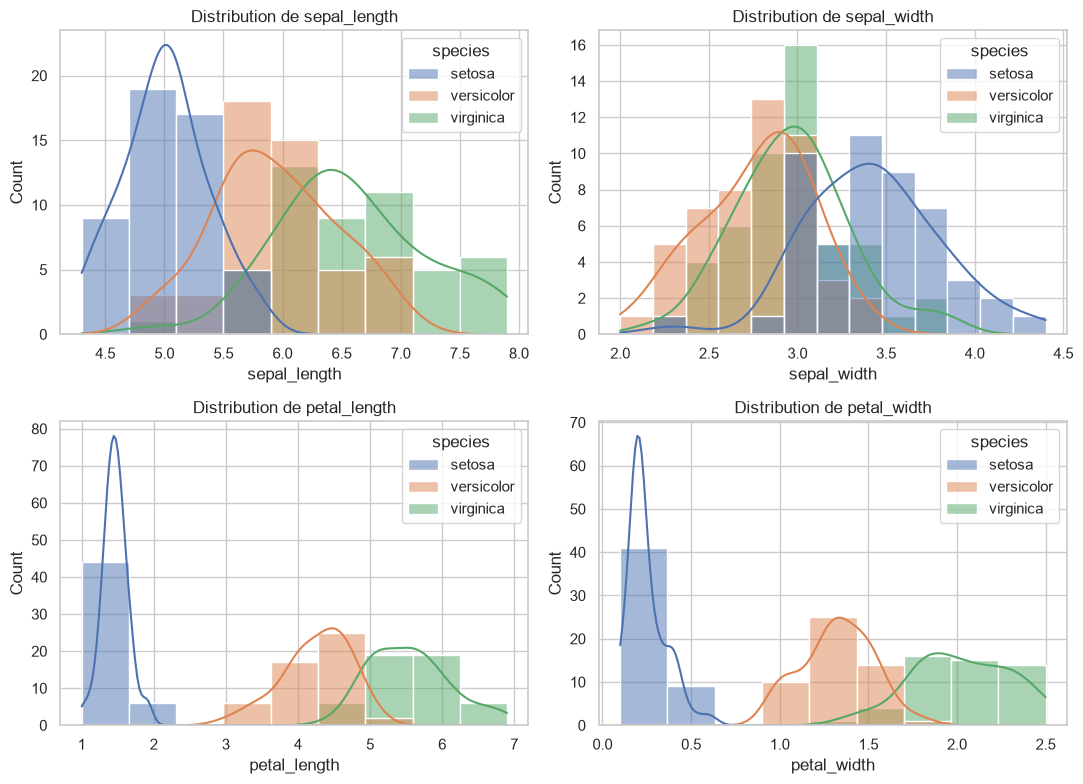

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

colonnes = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

for ax, col in zip(axes.flatten(), colonnes):
    sns.histplot(data=df, x=col, hue="species", kde=True, ax=ax)
    ax.set_title(f"Distribution de {col}")

plt.tight_layout()
plt.show()

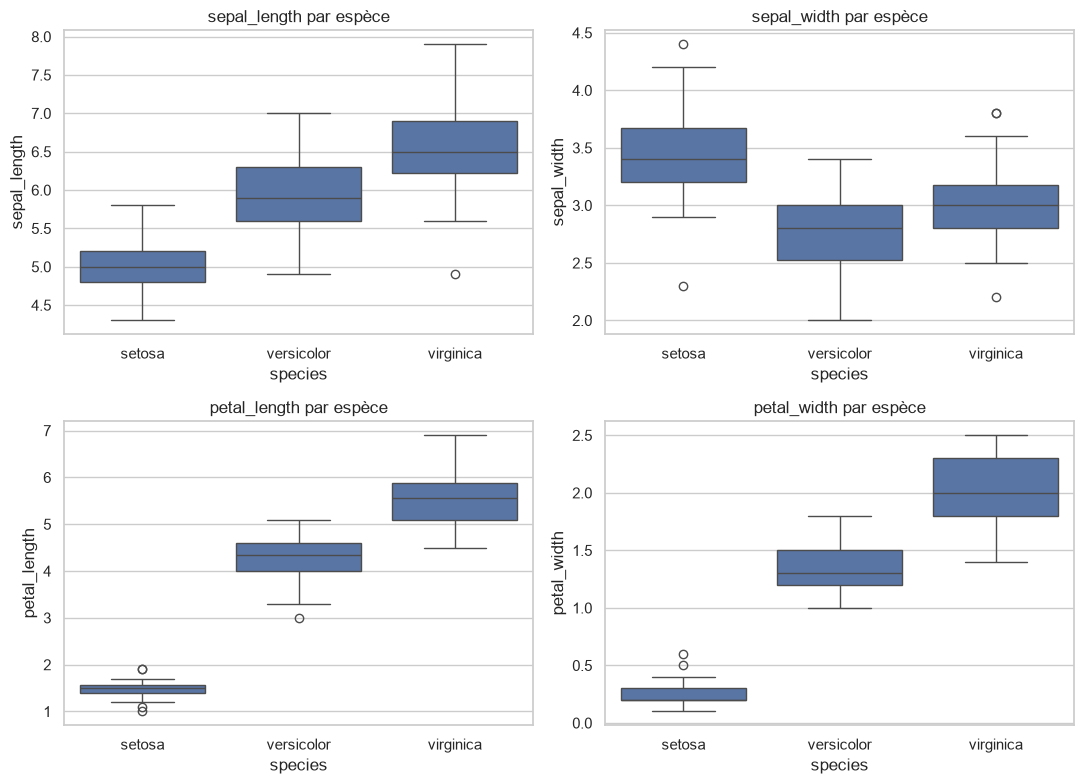

In [71]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, col in zip(axes.flatten(), colonnes):
    sns.boxplot(data=df, x="species", y=col, ax=ax)
    ax.set_title(f"{col} par espèce")

plt.tight_layout()
plt.show()

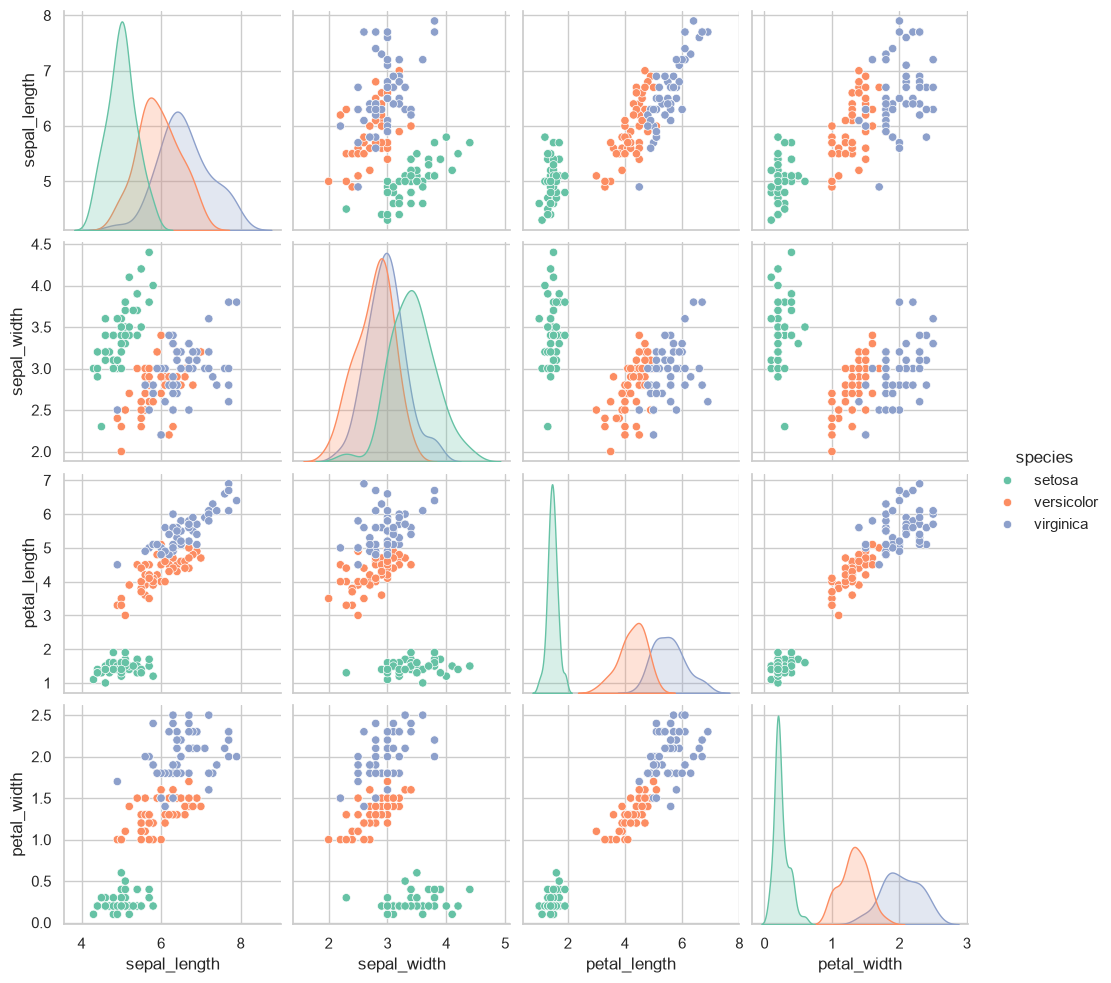

In [72]:
sns.pairplot(df, hue="species", palette="Set2")
plt.show()

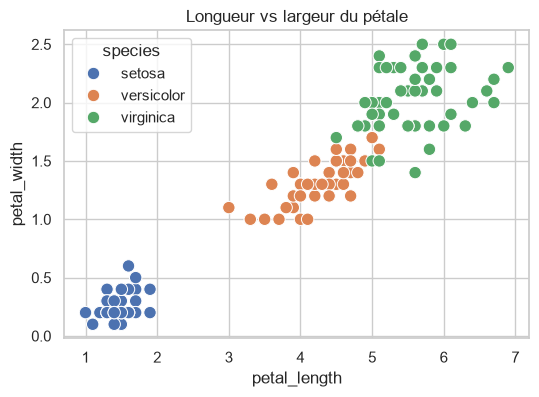

In [73]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="petal_length", y="petal_width",
                hue="species", s=80)
plt.title("Longueur vs largeur du pétale")
plt.show()

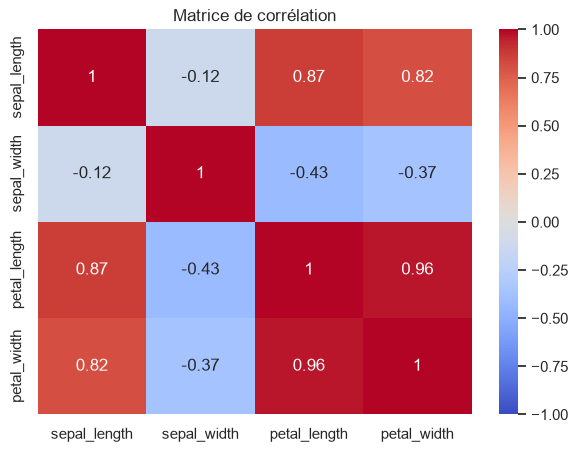

In [74]:
corr = df.drop(columns="species").corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.savefig("pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [75]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
X = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]]
y = df["species"]
print(X.shape)
print(y.shape)

(150, 4)
(150,)


In [76]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(le.classes_)
print(y_encoded[:5], y_encoded[-5:])

['setosa' 'versicolor' 'virginica']
[0 0 0 0 0] [2 2 2 2 2]


In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

print(np.bincount(y_train))
print(np.bincount(y_test))

X_train : (120, 4)
X_test  : (30, 4)
y_train : (120,)
y_test  : (30,)
[40 40 40]
[10 10 10]


In [78]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

[-0. -0.  0.  0.]
[1. 1. 1. 1.]


In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [80]:
models = {
    "Régression logistique": LogisticRegression(max_iter=200, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Arbre de décision": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
}

In [81]:
modeles_normalises = ["Régression logistique", "KNN", "SVM"]

In [82]:
predictions = {}

for nom, modele in models.items():
    if nom in modeles_normalises:
        modele.fit(X_train_scaled, y_train)
        predictions[nom] = modele.predict(X_test_scaled)
    else:
        modele.fit(X_train, y_train)
        predictions[nom] = modele.predict(X_test)

    print(f"{nom} : entraîné")

Régression logistique : entraîné
KNN : entraîné
Arbre de décision : entraîné
Random Forest : entraîné
SVM : entraîné


d:\CodeAlpha_IrisFlowerClassification\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [83]:
print("Réel     :", le.inverse_transform(y_test[:10]))
print("Prédit RF:", le.inverse_transform(predictions["Random Forest"][:10]))

Réel     : ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']
Prédit RF: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [84]:
resume = pd.DataFrame({"Réel": y_test})
for nom, pred in predictions.items():
    resume[nom] = pred

resume.head(10)

,Réel,Régression logistique,KNN,Arbre de décision,Random Forest,SVM
0,0,0,0,0,0,0
1,2,2,2,2,2,2
2,1,1,1,1,1,1
3,1,1,1,1,1,1
4,0,0,0,0,0,0
5,1,1,1,1,1,1
6,0,0,0,0,0,0
7,0,0,0,0,0,0
8,2,2,2,2,2,2
9,1,1,1,1,1,1


In [85]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

In [86]:
resultats = {}

for nom, pred in predictions.items():
    resultats[nom] = accuracy_score(y_test, pred)
    print(f"{nom} : {resultats[nom]:.2%}")

Régression logistique : 93.33%
KNN : 93.33%
Arbre de décision : 93.33%
Random Forest : 90.00%
SVM : 96.67%


In [87]:
nom_modele = "Random Forest"
cm = confusion_matrix(y_test, predictions[nom_modele])
print(cm)

[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


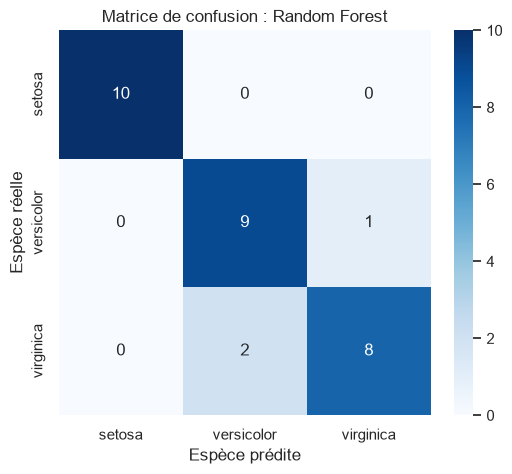

In [88]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Espèce prédite")
plt.ylabel("Espèce réelle")
plt.title(f"Matrice de confusion : {nom_modele}")
plt.show()

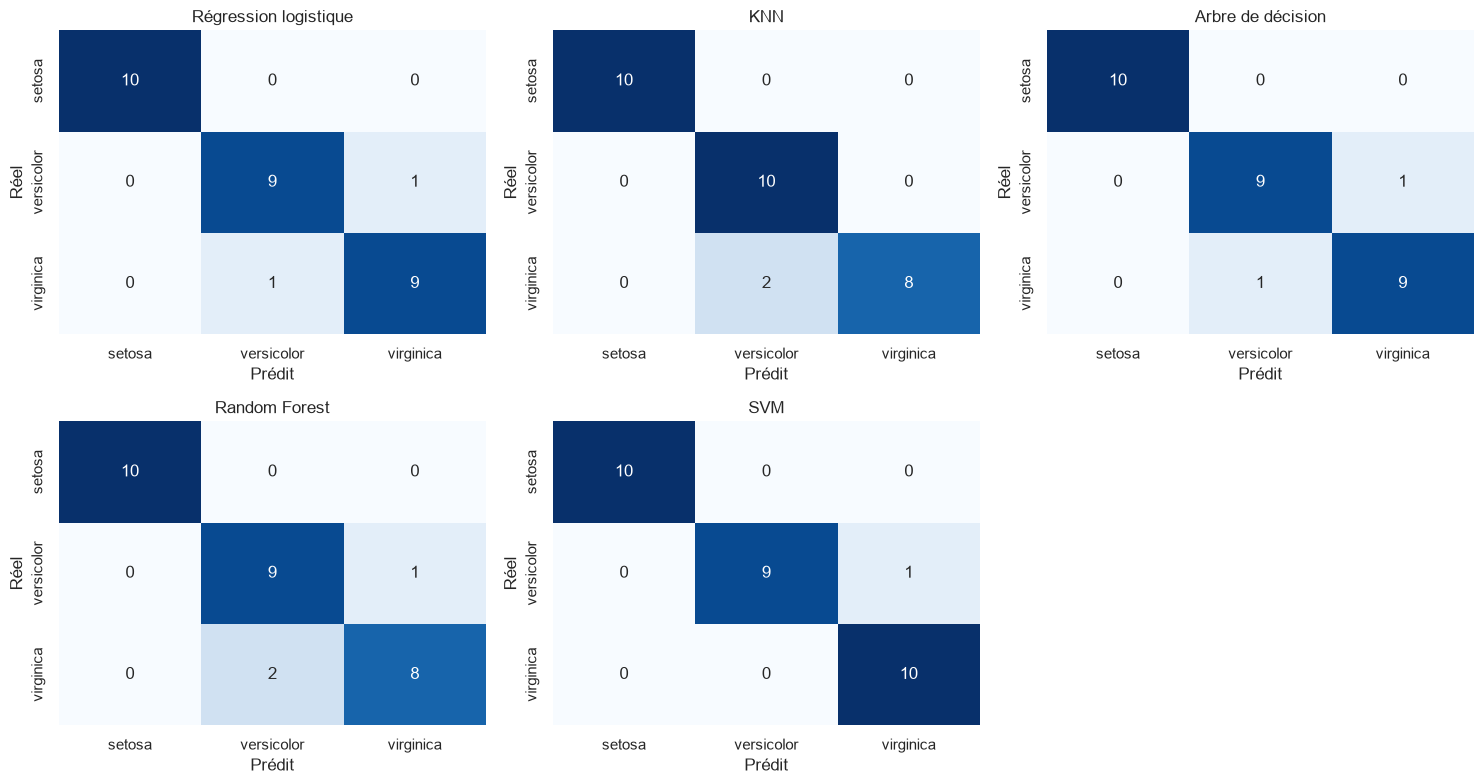

In [89]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (nom, pred) in zip(axes.flatten(), predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(nom)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")

axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

In [90]:
print(classification_report(y_test, predictions["Random Forest"],
                            target_names=le.classes_))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [91]:
for nom, pred in predictions.items():
    print(f"===== {nom} =====")
    print(classification_report(y_test, pred, target_names=le.classes_))

===== Régression logistique =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

===== KNN =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

===== Arbre de décision =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90      

In [92]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_cv = {}

for nom, modele in models.items():
    if nom in modeles_normalises:
        estimateur = make_pipeline(StandardScaler(), modele)
    else:
        estimateur = modele

    scores = cross_val_score(estimateur, X, y_encoded, cv=cv)
    scores_cv[nom] = scores
    print(f"{nom} : moyenne {scores.mean():.2%} (± {scores.std():.2%})")

Régression logistique : moyenne 95.33% (± 4.52%)
KNN : moyenne 97.33% (± 2.49%)
Arbre de décision : moyenne 95.33% (± 3.40%)
Random Forest : moyenne 94.67% (± 2.67%)


d:\CodeAlpha_IrisFlowerClassification\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\CodeAlpha_IrisFlowerClassification\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM : moyenne 96.00% (± 3.89%)


d:\CodeAlpha_IrisFlowerClassification\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\CodeAlpha_IrisFlowerClassification\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\CodeAlpha_IrisFlowerClassification\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [93]:
print(scores_cv["KNN"].round(3))

[1.    0.967 0.933 1.    0.967]


In [94]:
tableau = pd.DataFrame({
    "Accuracy test": pd.Series(resultats),
    "CV moyenne": pd.Series({nom: s.mean() for nom, s in scores_cv.items()}),
    "CV écart-type": pd.Series({nom: s.std() for nom, s in scores_cv.items()}),
})

tableau = tableau.sort_values("CV moyenne", ascending=False)
(tableau * 100).round(2)

,Accuracy test,CV moyenne,CV écart-type
KNN,93.33,97.33,2.49
SVM,96.67,96.00,3.89
Arbre de décision,93.33,95.33,3.40
Régression logistique,93.33,95.33,4.52
Random Forest,90.00,94.67,2.67


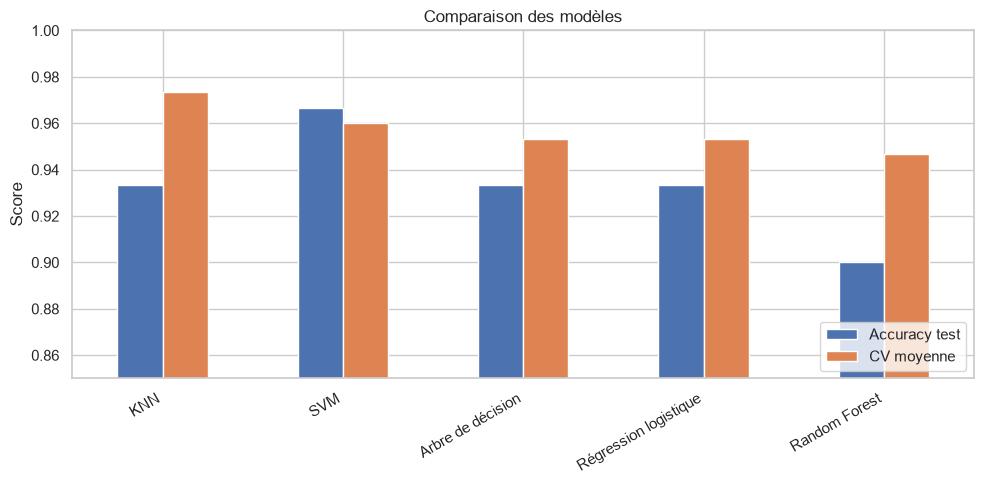

In [95]:
tableau[["Accuracy test", "CV moyenne"]].plot(kind="bar", figsize=(10, 5))
plt.title("Comparaison des modèles")
plt.ylabel("Score")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## **Choosing the Best Model**

**Selected model: KNN (`n_neighbors = 5`)**

**Reasons:**
1. Highest average cross-validation score (97.33%).
2. Lowest standard deviation (2.49), making it the most stable model.
3. Simple to explain: it classifies based on the 5 nearest flowers.

**Note:** The five models have similar performances (94.67% to 97.33% in cross-validation). With only 150 flowers, these differences are of the same order of magnitude as the variation between folds, so the models are generally equivalent. The accuracy on the test set (a single split of 30 flowers) is less reliable than cross-validation.

In [96]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [97]:
pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(random_state=42)),
])

param_svm = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__kernel": ["linear", "rbf"],
    "svm__gamma": ["scale", 0.1, 0.01],
}

grid_svm = GridSearchCV(pipe_svm, param_svm, cv=5, scoring="accuracy")
grid_svm.fit(X_train, y_train)

print("Meilleurs réglages :", grid_svm.best_params_)
print(f"Meilleur score (validation croisée) : {grid_svm.best_score_:.2%}")

Meilleurs réglages : {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Meilleur score (validation croisée) : 97.50%


In [98]:
pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

param_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13],
    "knn__weights": ["uniform", "distance"],
}

grid_knn = GridSearchCV(pipe_knn, param_knn, cv=5, scoring="accuracy")
grid_knn.fit(X_train, y_train)

print("Meilleurs réglages :", grid_knn.best_params_)
print(f"Meilleur score (validation croisée) : {grid_knn.best_score_:.2%}")

Meilleurs réglages : {'knn__n_neighbors': 5, 'knn__weights': 'uniform'}
Meilleur score (validation croisée) : 96.67%


In [99]:
for nom, grid in [("SVM optimisé", grid_svm), ("KNN optimisé", grid_knn)]:
    y_pred = grid.predict(X_test)
    print(f"{nom} : {accuracy_score(y_test, y_pred):.2%}")

SVM optimisé : 93.33%
KNN optimisé : 93.33%


In [100]:
resultats_grid = pd.DataFrame(grid_svm.cv_results_)
resultats_grid[["params", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score").head(5)

,params,mean_test_score,rank_test_score
0,"{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__k...",0.975,1
2,"{'svm__C': 0.1, 'svm__gamma': 0.1, 'svm__kerne...",0.975,1
6,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__ker...",0.975,1
4,"{'svm__C': 0.1, 'svm__gamma': 0.01, 'svm__kern...",0.975,1
9,"{'svm__C': 1, 'svm__gamma': 0.1, 'svm__kernel'...",0.975,1


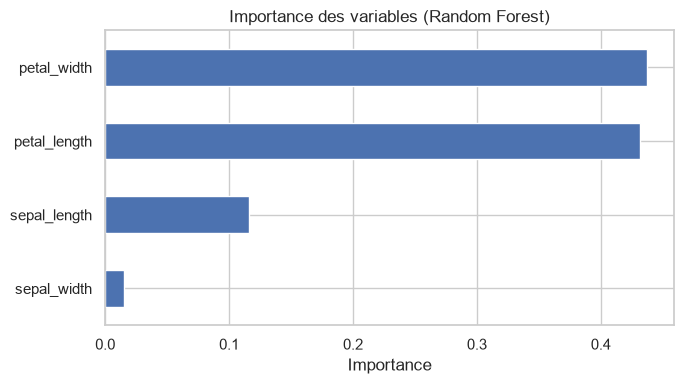

petal_width     0.437
petal_length    0.431
sepal_length    0.116
sepal_width     0.015
dtype: float64


In [101]:
rf = models["Random Forest"]

importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values()

importances.plot(kind="barh", figsize=(7, 4))
plt.title("Importance des variables (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(3))

In [102]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

modele_final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modele_final.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal_length','sepal_width','petal_length','petal_width']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [103]:
modele_final = grid_knn.best_estimator_
print(f"Accuracy test : {modele_final.score(X_test, y_test):.2%}")

Accuracy test : 93.33%


In [104]:
nouvelle_fleur = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=X.columns)
nouvelle_fleur

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


In [105]:
prediction = modele_final.predict(nouvelle_fleur)
espece = le.inverse_transform(prediction)[0]

print("Espèce prédite :", espece)

Espèce prédite : setosa


In [106]:
probabilites = modele_final.predict_proba(nouvelle_fleur)[0]

for nom, p in zip(le.classes_, probabilites):
    print(f"{nom} : {p:.0%}")

setosa : 100%
versicolor : 0%
virginica : 0%


In [107]:
def predire_espece(sepal_length, sepal_width, petal_length, petal_width):
    fleur = pd.DataFrame([[sepal_length, sepal_width, petal_length, petal_width]],
                         columns=X.columns)
    pred = modele_final.predict(fleur)
    proba = modele_final.predict_proba(fleur)[0]
    espece = le.inverse_transform(pred)[0]
    return espece, proba.max()

In [108]:
exemples = [
    (5.1, 3.5, 1.4, 0.2),
    (6.0, 2.9, 4.5, 1.5),
    (6.5, 3.0, 5.5, 1.8),
]

for mesures in exemples:
    espece, confiance = predire_espece(*mesures)
    print(f"{mesures} -> {espece} (confiance : {confiance:.0%})")

(5.1, 3.5, 1.4, 0.2) -> setosa (confiance : 100%)
(6.0, 2.9, 4.5, 1.5) -> versicolor (confiance : 100%)
(6.5, 3.0, 5.5, 1.8) -> virginica (confiance : 100%)


In [109]:
print(predire_espece(6.0, 2.8, 5.0, 1.7))

('virginica', np.float64(0.8))


In [110]:
import joblib

joblib.dump(modele_final, "iris_model.pkl")
joblib.dump(le, "label_encoder.pkl")

['label_encoder.pkl']

In [111]:
modele_charge = joblib.load("iris_model.pkl")
le_charge = joblib.load("label_encoder.pkl")

pred = modele_charge.predict(nouvelle_fleur)
print(le_charge.inverse_transform(pred)[0])

setosa


## Conclusion

### Objective
Classify Iris flowers (setosa, versicolor, virginica) using four measurements: sepal length, sepal width, petal length, and petal width.

### Methodology
1. Explored the 150 flowers: no missing values and three balanced classes.
2. Visualization: petal measurements provide the best separation between species.
3. Split the data into 80% training and 20% testing, followed by normalization.
4. Trained five models: Logistic Regression, KNN, Decision Tree, Random Forest, and SVM.
5. Evaluated the models using accuracy, confusion matrix, classification report, and cross-validation.

### Results
- Selected model: **KNN**, with a cross-validation mean score of 97.33% (± 2.49) and 93.33% accuracy on the test set.
- The five models achieved cross-validation scores ranging from 94.67% to 97.33%.
- Most important features: [your 2 features].
- GridSearchCV results: [your optimal parameters, or "the optimization did not lead to a significant improvement"].

### Observations
- Setosa is the easiest species to classify.
- Any misclassifications mainly involve versicolor and virginica, whose measurements overlap: [your observations].

### Limitations
- The dataset is very small (150 flowers): the test set contains only 30 flowers, meaning that a single misclassification changes the accuracy by 3.33 percentage points.
- Differences between models are of the same order of magnitude as the variation across folds; therefore, the models are generally comparable.
- The dataset is clean and relatively simple, so these results cannot automatically be generalized to real-world problems.

### Possible Improvements
- Test the models on a larger dataset.
- Try other models or hyperparameter settings.
- Repeat cross-validation to obtain more stable performance estimates.